# Lab 10: How to answer from documents with retrieval

## Goal

Answer a support rep's question from the shop's policy files: turn every file into an embedding, find the files
nearest to the question, and let the model answer only from those files, or say it does not know. The moment comes
in Part E. "When is support staffed?" puts `policy_support_reps.md` first and the file that holds the hours,
`policy_support_hours.md`, second. A search that keeps only the nearest file hands the model the wrong one, and the
model then says, politely and without any error, that the documents do not say. A question no file can answer, the
CEO's mobile number, still gets three "nearest" files. Nearest is not the same as relevant.

## What you will learn

- How to read an embedding: one vector of 1,536 numbers per text, of length 1.
- How to compute cosine similarity and squared distance by hand, and why, for vectors of length 1, they always put
  files in the same order (squared distance = 2 − 2 × cosine).
- How to split a long document into chunks whose ids point back to their source, and what a split by size breaks.
- How to store and search vectors in Chroma, reading the raw query result before a helper wraps it.
- How to answer only from the retrieved files and refuse otherwise, and how to narrow a search with a metadata
  filter.
- How to measure retrieval with hit@1 and hit@3 on labelled questions, and how to run Chroma as a server that keeps
  its data on disk.

## Where this lab starts

Labs 03 to 06 answered questions about a customer with lookups on the shop's database: Helena Holý's invoices are
rows in a table, and a SQL query finds them. A return window is not a row. It is a sentence in a policy file, and
there is nothing to query. Three questions, three places an answer can live:

| Question | Where the answer is | What to do |
|---|---|---|
| How many invoices does Helena Holý have? | `data/chinook.db`, the `invoices` table | Query the database with a tool |
| How long do I have to return an unopened CD? | `data/corpus/policy_returns.md` | Find the file, then answer from it (this lab) |
| What is Chinook's revenue target for 2014? | Nowhere in this repository | Say you do not know |

Searching the files for Helena's invoice count would find a policy that mentions invoices, not the number 7.
Retrieval is for text you cannot query, not a default for every question. This lab needs nothing from earlier labs;
it restates what it uses.

Finding the nearest files and answering from them is called **retrieval-augmented generation (RAG)**. The picture
below is the whole pipeline. The black boxes are model calls (an embedding model, then the chat model); the lime
boxes are our code.

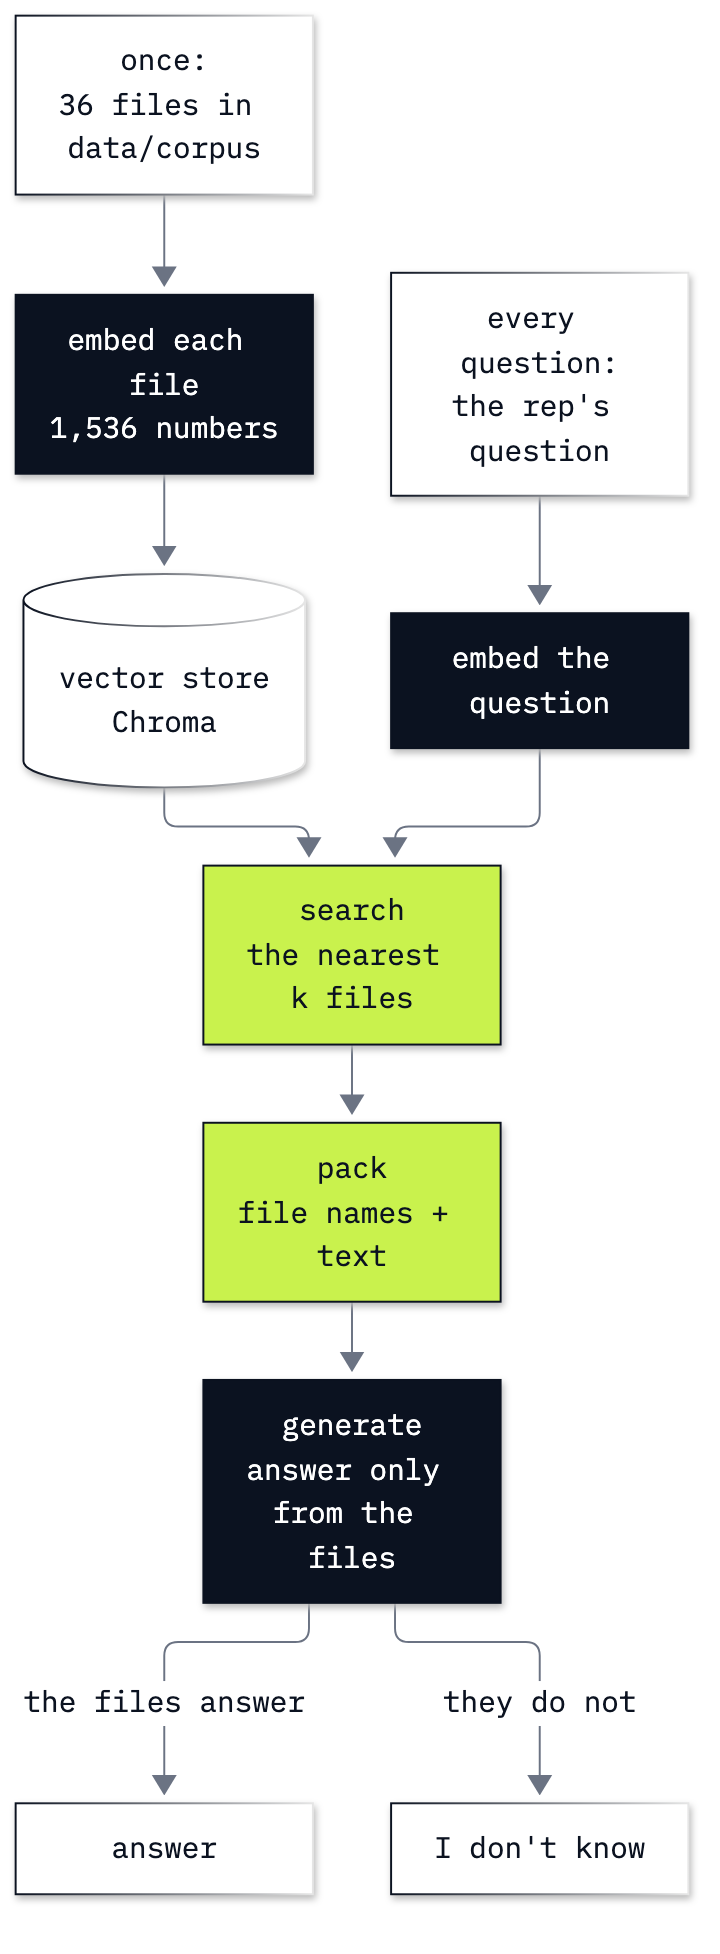

In [1]:
from IPython.display import Image

Image("resources/lab10_retrieve_then_generate.png", width=440)

Read it in two halves. Once, every file is embedded (turned into a list of numbers) and stored. Then, for every
question: the question is embedded the same way, the store returns the k nearest files, our code packs them with
their names, and the model answers from them or says it does not know. Parts A and B build the embedding and the
search by hand, Part C decides what one stored entry is, Part D moves the search into a vector store, Part E adds the
answer, Parts F and G sharpen and measure the search, and Part H runs the store as a server.

---

## Setup

The config cell is the same in every lab: it finds the repository folder by `models.env`, reads the models and the
prices from there, and finds your key without printing it (Lab 00 reads it line by line).

In [2]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


Next, the client, the embedding model and its price, both from `models.env`, and the 36 files of `data/corpus/`: 20
policies (the shop's rules) and 16 support tickets (cases where a rule was applied). We read them in place and never
change them.

In [3]:
from openai import OpenAI, omit

client = OpenAI()
EMBEDDING_MODEL = settings["EMBEDDING_MODEL"]
PRICE_EMBEDDING = float(settings["PRICE_EMBEDDING_PER_MILLION"])

CORPUS = ROOT / "data" / "corpus"
files = sorted(CORPUS.glob("*.md"))
print(len(files), "files:",
      sum(p.name.startswith("policy_") for p in files), "policies,",
      sum(p.name.startswith("ticket_") for p in files), "tickets")
print([p.name for p in files[:3]], "...")

36 files: 20 policies, 16 tickets
['policy_accounts.md', 'policy_cancellations.md', 'policy_damaged_media.md'] ...


---

## Part A: Represent a policy as an embedding

A program cannot read 36 files and judge which one answers a question; it needs every text turned into something it
can compare. This part turns one policy into an embedding and reads what comes back.

First the file itself, as a rep would read it.

In [4]:
returns_text = (CORPUS / "policy_returns.md").read_text()
print(returns_text)

# Returns

Physical items (CDs, vinyl, boxed sets) may be returned within 30 days of the invoice date if unopened.

Opened physical media can be returned within 14 days only if the disc is defective. A replacement is preferred over a refund.

Digital downloads and streamed albums cannot be returned. See policy_digital_downloads.md.

Start a return by writing to support. Include the invoice number. Support will reply within the SLA in policy_support_hours.md.



Four rules: 30 days for an unopened physical item, 14 days for an opened one only if it is defective, no returns on
digital albums, and how to start a return. Our question, *How long do I have to return an unopened CD?*, is answered
by the first rule. We found it by reading. The program needs another way to find "the file about returns" among 36.

### An embedding is a list of numbers

An embedding model reads a whole text once and returns a fixed-length list of numbers. Texts with similar meaning get
lists that are close to each other, even when they share no words; unrelated texts get lists far apart. The call is
`client.embeddings.create`, a different endpoint from the chat calls of earlier labs: it writes no text, it only
returns numbers.

In [5]:
response = client.embeddings.create(model=EMBEDDING_MODEL, input=returns_text)
returns_vec = response.data[0].embedding

print(type(returns_vec).__name__, "of", len(returns_vec), "numbers")
print("first 8:", [round(x, 4) for x in returns_vec[:8]])
print("tokens read:", response.usage.prompt_tokens)

list of 1536 numbers
first 8: [-0.0125, 0.0665, 0.0211, -0.0012, 0.0079, 0.0047, -0.0146, -0.0093]
tokens read: 97


Reading the output:

- `response.data` is a list with one item per input text. We sent one text, so `data[0]` is ours, and `.embedding`
  is its vector.
- **A list of 1,536 floats:** one vector for the whole file. A one-line question and a long file both get exactly
  1,536 numbers; that fixed length is what makes them comparable.
- **The first eight numbers** are small, some positive and some negative. No single number means anything a person
  can read (there is no "returns" position). Only the whole list, compared with another list, carries meaning.
- **97 tokens read:** embeddings are billed by the tokens read, at the embedding price in `models.env`
  (0.02 US dollars per million tokens).

### The length of the vector

A vector's length (its norm) is the square root of the sum of its squared numbers, Pythagoras in 1,536 dimensions.

In [6]:
import math

length = math.sqrt(sum(x * x for x in returns_vec))
print("length:", round(length, 4))

length: 0.9999


0.9999: the vector has length 1, give or take rounding in the last digits. OpenAI's embedding models return
vectors **normalised to length 1**, so every text, short or long, becomes a point on the same sphere and only the
direction differs. Part B uses this fact.

We will embed many more texts, so a small function repeats the call we just made and returns only the vector:

In [7]:
def embed(text):
    return client.embeddings.create(model=EMBEDDING_MODEL, input=text).data[0].embedding

**Checkpoint A.** One file became a `list` of 1,536 numbers of length 0.9999. A pass shows the shape of an
embedding; it does not yet show that nearby vectors mean nearby meaning. That needs a way to measure "nearby".

---

## Part B: Compare two embeddings by hand

A vector alone tells us nothing; a search needs a ruler that says how close two vectors are. This part builds two
rulers by hand, first on vectors small enough to check in your head, then on real embeddings, and ends with a search
over all 36 files.

### Two rulers on three small vectors

Take three vectors with two numbers each, all of length 1: `a = [1, 0]` points east, `c = [0, 1]` points north, and
`b = [0.8, 0.6]` sits between them, closer to east ($0.8^2 + 0.6^2 = 1$).

- **Cosine similarity** measures the angle between two vectors: $\cos(a, b) = \dfrac{\sum_i a_i b_i}{|a|\,|b|}$,
  the dot product divided by the two lengths. 1 means the same direction, 0 means unrelated (a right angle).
  **Bigger is nearer.**
- **Squared distance** is the straight-line distance between the two points, squared: $d^2(a, b) = \sum_i (a_i -
  b_i)^2$. 0 means the same point. **Smaller is nearer.**

In [8]:
def cosine(a, b):
    dot = sum(x * y for x, y in zip(a, b))
    return dot / (math.sqrt(sum(x * x for x in a)) * math.sqrt(sum(y * y for y in b)))


def squared_distance(a, b):
    return sum((x - y) ** 2 for x, y in zip(a, b))


a, b, c = [1, 0], [0.8, 0.6], [0, 1]
print("a vs b: cosine", round(cosine(a, b), 4), "| squared distance", round(squared_distance(a, b), 4))
print("a vs c: cosine", round(cosine(a, c), 4), "| squared distance", round(squared_distance(a, c), 4))

a vs b: cosine 0.8 | squared distance 0.4
a vs c: cosine 0.0 | squared distance 2


`zip(a, b)` pairs the numbers in the same position, the first with the first and the second with the second, which is
what both formulas need. Check the first line by hand:

- cosine: $1 \times 0.8 + 0 \times 0.6 = 0.8$ (both lengths are 1, so there is nothing to divide by);
- squared distance: $(1 - 0.8)^2 + (0 - 0.6)^2 = 0.04 + 0.36 = 0.40$.

Now notice that $0.40 = 2 - 2 \times 0.8$, and on the second line $2 = 2 - 2 \times 0$. That is not a coincidence. For
two vectors of length 1, $d^2 = |a|^2 + |b|^2 - 2\,a \cdot b = 2 - 2\cos(a, b)$. **For vectors of length 1, the two
rulers always put things in the same order:** the higher the cosine, the smaller the distance. A store that ranks by
squared distance and one that ranks by cosine return the same files.

### The same rulers on real embeddings

Three sentences. `sample` is our question. `near` asks the same thing in other words and shares **no word** with it:
a sealed vinyl record instead of an unopened CD, "sending back" instead of "return". `far` is about something else.
If embeddings capture meaning, `near` should come out close to `sample` and `far` should not.

In [9]:
sample = "How long do I have to return an unopened CD?"
near = "What's the deadline for sending back a sealed vinyl record?"
far = "What's the weather like in Prague today?"

sample_vec, near_vec, far_vec = embed(sample), embed(near), embed(far)
for name, vec in [("near", near_vec), ("far", far_vec)]:
    cos = cosine(sample_vec, vec)
    print(f"sample vs {name}: cosine {cos:.4f} | squared distance {squared_distance(sample_vec, vec):.4f}"
          f" | 2 - 2 x cosine {2 - 2 * cos:.4f}")

sample vs near: cosine 0.6280 | squared distance 0.7444 | 2 - 2 x cosine 0.7440
sample vs far: cosine 0.0006 | squared distance 1.9991 | 2 - 2 x cosine 1.9989


Reading the two lines:

- `near` scores a cosine of **0.6280** against the question it paraphrases, with no word in common; `far`
  scores **0.0006**, practically zero. The embedding placed the two return questions together by meaning.
- 0.6280 is not close to 1. Even a close paraphrase lands well below 1 with this model; the scale is the
  model's own. Read a cosine against other cosines from the same model, never against 1.
- The last two columns agree: 0.7444 against 0.7440 for `near`, 1.9991 against 1.9989 for `far`. The identity $d^2 = 2 - 2\cos$ holds on real embeddings too, to
  about three decimals; the small gap is there because the lengths are 1 only to about four decimals (Part A printed
  0.9999).

### One question against all 36 files

Before any library: the squared distance between our question and `policy_returns.md`, by hand. Remember this number;
Part D asks a vector store the same question.

In [10]:
print("by hand:", round(squared_distance(sample_vec, returns_vec), 4))

by hand: 0.7721


Now all 36 files. `input` also takes a list of texts: one call returns one vector per text, **in the same order**.
We keep the texts, their file names and their vectors in three lists built from the same `files` list.

In [11]:
import numpy as np

texts = [p.read_text() for p in files]
names = [p.name for p in files]
response = client.embeddings.create(model=EMBEDDING_MODEL, input=texts)
vectors = [item.embedding for item in response.data]

D = np.array(vectors)
tokens = response.usage.prompt_tokens
print("D shape:", D.shape)
print("tokens read:", tokens, f"| cost: ${tokens * PRICE_EMBEDDING / 1_000_000:.6f}")

D shape: (36, 1536)
tokens read: 2551 | cost: $0.000051


`np.array(vectors)` turns the list of 36 lists into a matrix `D` of shape **(36, 1536)**:

- **36 rows:** one vector per file. Row `i` belongs to `names[i]` and `texts[i]`.
- **1,536 columns:** the numbers of each vector.

The whole folder cost 0.000051 US dollars to embed (2,551 tokens).

> **⚠️ Keep vectors and names aligned.** The three lists come from the same `files` list in the same order. If one of
> them were sorted on its own, `D` would keep its shape and the search below would still run, but its results would
> point at the wrong files.

Think of `D` as a very simple **in-memory vector store**. Searching it is one line: `D @ q` multiplies every row by
the question's vector and adds up the products, which gives 36 dot products, one per file. Every vector has length 1,
so each dot product is a cosine.

In [12]:
q = np.array(sample_vec)
scores = D @ q
top = np.argsort(-scores)[:3]
for i in top:
    print(f"cosine {scores[i]:.4f}  {names[i]}")

cosine 0.6134  policy_returns.md
cosine 0.4638  policy_warranty.md
cosine 0.4298  policy_damaged_media.md


`np.argsort(-scores)` lists the row positions from the highest score to the lowest (the minus sign turns "sort
ascending" into "highest first"), and `[:3]` keeps the three nearest. `policy_returns.md` comes first at
**0.6134**, followed by `policy_warranty.md` (0.4638) and `policy_damaged_media.md` (0.4298). The second and third files share the topic (physical media) but not the
answer: a search returns what is near, and nearness is all it knows.

That is the whole of a vector search. A vector store does the same, plus what our variable does not: it keeps the
text and labels with each vector, finds the nearest quickly when there are millions, and keeps everything after the
program stops. Before storing anything, one decision: what is one entry? Here, a whole file.

**Checkpoint B.** The small vectors give 0.40 = 2 − 2 × 0.8; on real embeddings $d^2$ and $2 - 2\cos$ agree to
about three decimals; `D` is (36, 1536); the search by hand puts `policy_returns.md` first.

---

## Part C: Split a long document into chunks that keep their source

Our files are short and each holds one topic, so one file can be one entry. A real company handbook is forty pages:
one vector for all of it would average every topic into one point, and the search could only ever say "the
handbook". Long documents are split into **chunks**, the pieces that get one vector each, and every chunk must say
where it came from, so an answer can be traced back to its source. To see what can go wrong, we build a handbook in
memory: the 20 policies joined into one text, as if they had arrived as a single document. Nothing is written to disk.

In [13]:
policy_files = [p for p in files if p.name.startswith("policy_")]
handbook = "\n\n".join(p.read_text().strip() for p in policy_files)
print(len(policy_files), "policies joined:", len(handbook), "characters")
print(handbook[:330])

20 policies joined: 6649 characters
# Accounts

An account is the email plus the customer record. One email, one account.

A customer can change their email once per calendar year. Invoices already issued keep the old email as a snapshot.

Account deletion: we remove the login and the marketing flag. Invoices stay. Support tickets stay for 24 months, then they are


One string of 6,649 characters. Each policy still starts with its `# ` heading line, but the file names are gone:
from here on, only the text says which policy a sentence belongs to.

### A split by size

The simplest split cuts every 300 characters. `range(0, len(handbook), SIZE)` gives the start positions 0, 300, 600
and so on, and `handbook[start:start + SIZE]` takes the 300 characters from each. Each chunk's id records its
character range, so it points back to where it came from in the handbook.

In [14]:
SIZE = 300
fixed_chunks = []
for start in range(0, len(handbook), SIZE):
    fixed_chunks.append({"id": f"handbook[{start}:{start + SIZE}]", "text": handbook[start:start + SIZE]})

print(len(fixed_chunks), "chunks")
for chunk in fixed_chunks[2:4]:
    print("---", chunk["id"])
    print(chunk["text"])

23 chunks
--- handbook[600:900]
o cancel, write to support with the invoice number the same day if you can.

# Damaged media

If a CD or vinyl arrives cracked, warped, or will not play, we replace it at no charge. Photograph the damage. Keep the original copy until the replacement arrives, then recycle it.

If the same title arriv
--- handbook[900:1200]
es damaged twice, offer a refund instead of a third copy.

# Data retention

Invoices: kept for 7 years (tax).

Support tickets: 24 months, then deleted.

Download logs: 12 months.

Marketing flags: until the customer opts out or the account is deleted.

We do not keep call recordings. This shop's s


Read where chunk `handbook[600:900]` ends and the next one starts: *"If the same title arriv"* | *"es damaged twice,
offer a refund instead of a third copy."* The split has cut a rule in half:

1. Neither chunk holds the whole rule. A search for "damaged twice" can find only half of it.
2. The second half has lost its heading. Chunk `handbook[900:1200]` starts mid-word and carries the end of *Damaged
   media* and the start of *Data retention*; nothing in it says which policy "offer a refund" belongs to. A model
   reading it would see a refund rule with no subject.
3. Its id points to characters 900 to 1200, not to a policy a rep could open and check.

### A split by headings

The handbook has a structure the size split ignored: every policy starts with a line beginning `# `. A loop over the
lines starts a new section at each heading and adds every other line to the current section.

In [15]:
sections = []
for line in handbook.splitlines():
    if line.startswith("# "):
        sections.append({"section": line[2:], "lines": []})
    sections[-1]["lines"].append(line)

heading_chunks = []
for number, section in enumerate(sections):
    heading_chunks.append({
        "id": f"handbook#{number:02d}",
        "section": section["section"],
        "text": "\n".join(section["lines"]).strip(),
    })

print(len(heading_chunks), "chunks")
print(heading_chunks[2])

20 chunks
{'id': 'handbook#02', 'section': 'Damaged media', 'text': '# Damaged media\n\nIf a CD or vinyl arrives cracked, warped, or will not play, we replace it at no charge. Photograph the damage. Keep the original copy until the replacement arrives, then recycle it.\n\nIf the same title arrives damaged twice, offer a refund instead of a third copy.'}


20 chunks, one per section. Each is a dictionary with three fields:

| Field | Holds | Who reads it |
|---|---|---|
| `id` | `handbook#02`: the document and the section number | our code, to find the chunk again and to cite it |
| `section` | `Damaged media`: the heading | a person checking an answer, and metadata filters (Part F) |
| `text` | the whole section, heading included | the embedding model, and later the chat model |

The damaged-twice rule is whole, under its own heading, and the chunk says where it came from.

The heading split gives back exactly the 20 policies, which is how the files on disk are already split: one policy
per file. So from Part D on we store the 36 files as they are, one file per chunk, with the **file name as the id**
that points back to the source.

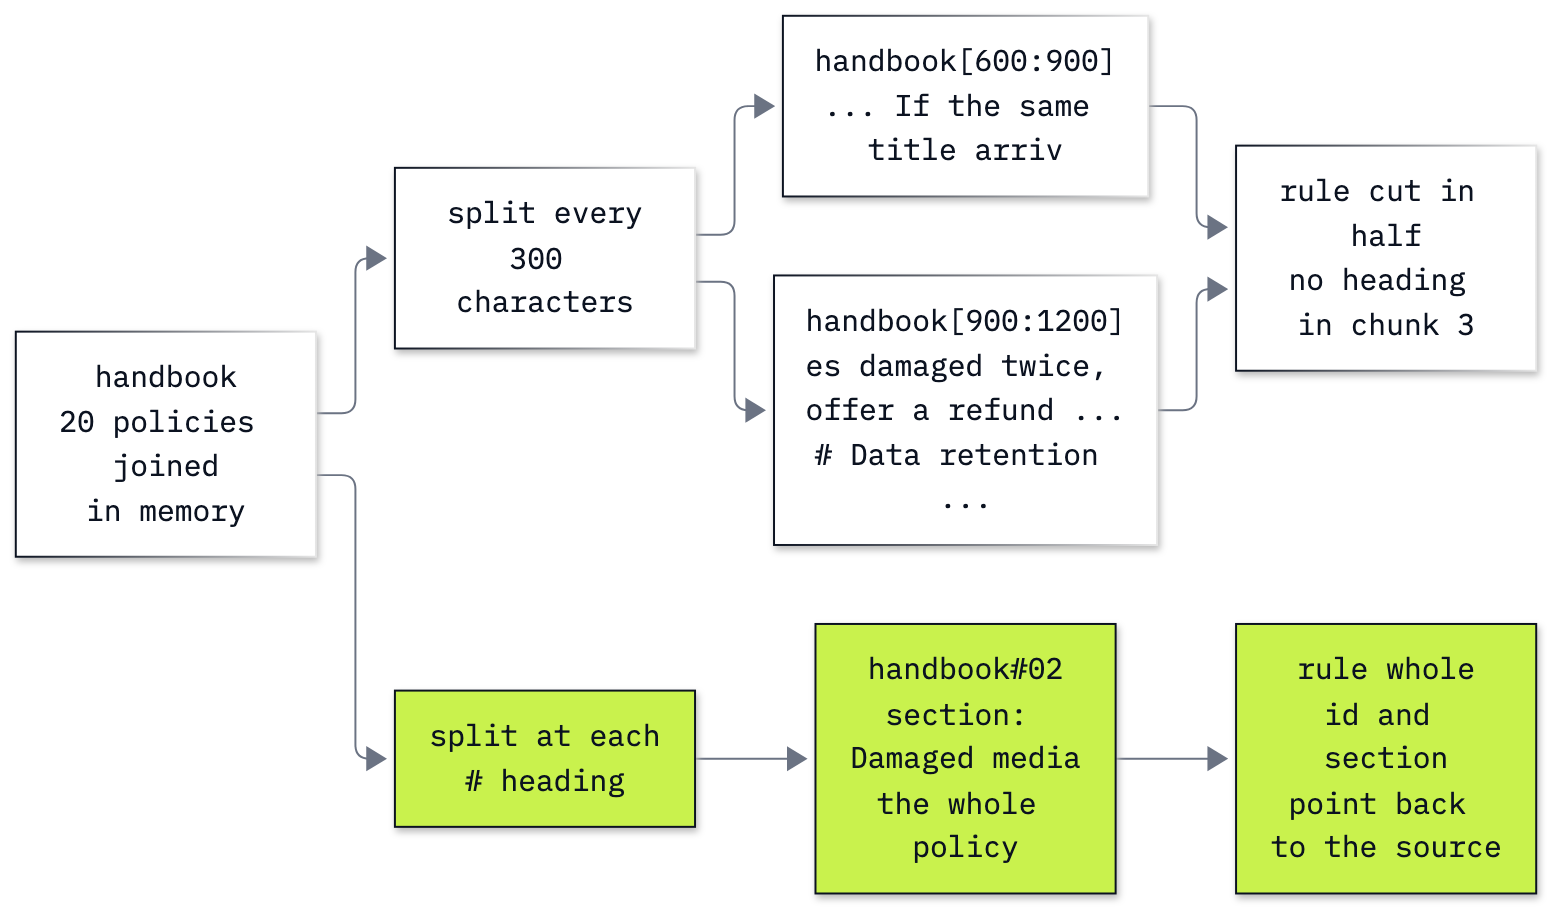

In [16]:
Image("resources/lab10_chunks_keep_their_source.png", width=760)

**In production:** split on the document's structure first (headings, then paragraphs), cap the chunk size, and let
neighbouring chunks overlap a little so a sentence near a boundary appears whole in one of them. LangChain's text
splitters and LlamaIndex's node parsers (Lab 12) do this. Smaller chunks can also find a rule more precisely than a
whole file; the challenge measures it.

**Checkpoint C.** 23 chunks by size, with the damaged-twice rule cut between `handbook[600:900]` and
`handbook[900:1200]`; 20 chunks by heading, with `handbook#02` holding *Damaged media* whole.

---

## Part D: Store and search the files in Chroma

Part B's search worked because we kept `D`, `names` and `texts` in three variables and kept them aligned ourselves.
A **vector store** keeps each vector together with its id, its text and its labels, and searches them for us.
**Chroma** is an open-source vector store; in this part it runs inside this Python process.

A Chroma record has four parts, passed as four lists aligned by position, like ours. Here is the first record before
we add it:

In [17]:
metadatas = [{"kind": name.split("_")[0]} for name in names]

print("id:      ", names[0])
print("metadata:", metadatas[0])
print("document:", texts[0][:60].replace("\n", " "), "...")
print("vector:  ", len(vectors[0]), "numbers")

id:       policy_accounts.md
metadata: {'kind': 'policy'}
document: # Accounts  An account is the email plus the customer record ...
vector:   1536 numbers


- **id:** the file name, which points back to the source (Part C).
- **metadata:** labels we choose. `name.split("_")[0]` takes the text before the first underscore, so every file is
  labelled `policy` or `ticket`. Part F searches on it.
- **document:** the text, returned with every result so we never look it up again.
- **vector:** the embedding we already paid for in Part B.

Now the store: a client, a collection (Chroma's name for a table of records) and one `add` with the four lists.

In [18]:
import chromadb

chroma = chromadb.EphemeralClient()
collection = chroma.get_or_create_collection("corpus")
collection.add(ids=names, documents=texts, metadatas=metadatas, embeddings=vectors)

print("stored:", collection.count())
print("distance:", collection.configuration["hnsw"]["space"])

stored: 36
distance: l2


- `EphemeralClient` keeps the collection in this process's memory: restart the kernel and it is gone (Part H keeps it
  on disk). `get_or_create_collection` returns the collection if it already exists, so running the cell again does
  not fail on the name.
- We passed our own vectors, so Chroma embeds nothing: OpenAI embeds, Chroma stores and ranks.
- `l2` is Chroma's default ruler, squared distance, the second ruler of Part B. Chroma can rank by cosine instead
  (`configuration={"hnsw": {"space": "cosine"}}` when the collection is created); for vectors of length 1 the order
  is the same, as Part B showed.

### Query the collection directly

A search is two steps: turn the question into a vector, then ask the collection for the nearest vectors.

Let's break this apart:
```python
QUESTION = "How long do I have to return an unopened CD?"
q = embed(QUESTION)
```

We first embed the question's text.

In [19]:
QUESTION = "How long do I have to return an unopened CD?"
q = embed(QUESTION)

We then query the collection by passing the query embedding

In [20]:
got = collection.query(query_embeddings=[q], n_results=3)
got

{'ids': [['policy_returns.md',
   'policy_warranty.md',
   'policy_damaged_media.md']],
 'embeddings': None,
 'documents': [['# Returns\n\nPhysical items (CDs, vinyl, boxed sets) may be returned within 30 days of the invoice date if unopened.\n\nOpened physical media can be returned within 14 days only if the disc is defective. A replacement is preferred over a refund.\n\nDigital downloads and streamed albums cannot be returned. See policy_digital_downloads.md.\n\nStart a return by writing to support. Include the invoice number. Support will reply within the SLA in policy_support_hours.md.\n',
   '# Warranty on physical media\n\nManufacturing defects are covered for 90 days from the invoice date. This is separate from the return window.\n\nWear from ordinary play (scratches, a warped sleeve from sunlight) is not a defect.\n\nWe do not warranty third-party players, needles, or headphones sold as add-ons after 30 days.\n',
   '# Damaged media\n\nIf a CD or vinyl arrives cracked, warped, 

Notice the keys

In [21]:
got.keys()

dict_keys(['ids', 'embeddings', 'documents', 'uris', 'included', 'data', 'metadatas', 'distances'])

What each key holds in this result:

| Key | Here |
|---|---|
| `ids` | the three file names, nearest first |
| `distances` | the squared distance of each, smaller is nearer |
| `documents` | the three texts |
| `metadatas` | the three `{"kind": ...}` labels |
| `included` | which of the fields above were filled in |
| `embeddings` | `None`: vectors are not sent back unless asked for (`include=["embeddings"]`) |
| `uris`, `data` | `None`: for images and other data we do not store |

**Why is every field a list of lists?** `query_embeddings` takes a *list* of questions, so one call can search for
several at once, and the result holds one inner list per question. We sent one question, so `got["ids"][0]` is the
list of ids for our question, and `got["ids"][0][0]` is its nearest file. `zip` pairs the ids and distances by
position:

In [22]:
for file_id, distance in zip(got["ids"][0], got["distances"][0]):
    print(f"{distance:.4f}  {file_id}")

0.7736  policy_returns.md
1.0717  policy_warranty.md
1.1401  policy_damaged_media.md


`policy_returns.md` is first at **0.7736**. By hand, in Part B, we got 0.7721: the same to two
decimals. The small gap is not Chroma's. The returns file was embedded twice, alone in Part A (the vector we used by
hand) and in the batch of 36 in Part B (the vector Chroma stores), and the two calls did not return exactly the same
numbers: Part B's search by hand, on the batch vector, gave a cosine of 0.6134, which is a squared distance of
2 − 2 × 0.6134 = 0.7732. The question was embedded twice as well (as `sample` in Part B, as `QUESTION`
here), which accounts for the last few ten-thousandths. Embedding the same text twice can move the third decimal;
here it did not move the order. Chroma did nothing we could not do ourselves; it does it for us, and quickly. The order matches Part B's
cosines (returns, warranty, damaged media), and $1 - d^2/2$ turns each distance back into its cosine (0.6132 for the first file).

### A helper that returns the same thing

Every search from here on repeats those two steps and the `[0]`, so a small function does it. `retrieve` returns the
same ids, distances and documents as the raw result, one dictionary per file, for one question.

In [23]:
def retrieve(question, k=3):
    got = collection.query(query_embeddings=[embed(question)], n_results=k)
    rows = []
    for i in range(len(got["ids"][0])):
        rows.append({
            "id": got["ids"][0][i],
            "distance": got["distances"][0][i],
            "document": got["documents"][0][i],
        })
    return rows


for row in retrieve(QUESTION):
    print(f"{row['distance']:.4f}  {row['id']}")

0.7736  policy_returns.md
1.0717  policy_warranty.md
1.1401  policy_damaged_media.md


The same three files at the same distances as the raw query.

**Checkpoint D.** `stored: 36`; the raw result has the keys `ids`, `embeddings`, `documents`, `uris`, `included`,
`data`, `metadatas` and `distances`, each a list with one inner list per question; `policy_returns.md` first at
0.7736, the hand value (0.7721) to two decimals.

---

## Part E: Answer only from what was retrieved

Retrieval returns files; the rep wants a sentence. The generate step puts the retrieved files in the prompt and asks
the model to answer only from them. It is also the step that has to say "I do not know".

### Pack the files

We put each retrieved file under its name in square brackets, nearest first, so the model (and anyone checking the
reply) can tell which file a fact came from.

In [24]:
hits = retrieve(QUESTION)
packed = "\n\n".join(f"[{row['id']}]\n{row['document']}" for row in hits)
print(packed)

[policy_returns.md]
# Returns

Physical items (CDs, vinyl, boxed sets) may be returned within 30 days of the invoice date if unopened.

Opened physical media can be returned within 14 days only if the disc is defective. A replacement is preferred over a refund.

Digital downloads and streamed albums cannot be returned. See policy_digital_downloads.md.

Start a return by writing to support. Include the invoice number. Support will reply within the SLA in policy_support_hours.md.


[policy_warranty.md]
# Warranty on physical media

Manufacturing defects are covered for 90 days from the invoice date. This is separate from the return window.

Wear from ordinary play (scratches, a warped sleeve from sunlight) is not a defect.

We do not warranty third-party players, needles, or headphones sold as add-ons after 30 days.


[policy_damaged_media.md]
# Damaged media

If a CD or vinyl arrives cracked, warped, or will not play, we replace it at no charge. Photograph the damage. Keep the original 

Packing keeps the order and labels each file; it does not summarise, rewrite or judge the files. The model will see
the three files and nothing else from the folder.

### One answer by hand

The rules go in the system message: answer only from the documents, and say so when they do not answer. The user
message holds the packed files and the question. `reasoning_effort=EFFORT or omit` sends the effort from `models.env`,
or leaves the argument out (`omit`) for a model without one.

In [25]:
RULES = ("Answer the question using only the documents below. "
         "If they do not contain the answer, say you do not know.")

response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": RULES},
        {"role": "user", "content": f"Documents:\n\n{packed}\n\nQuestion: {QUESTION}"},
    ],
    max_completion_tokens=200,
    reasoning_effort=EFFORT or omit,
)
print(response.choices[0].message.content)
print("prompt tokens:", response.usage.prompt_tokens)

You have 30 days from the invoice date to return an unopened CD.
prompt tokens: 290


The 30-day rule, from the first file. The prompt was 290 tokens: three files and a question, not the
whole folder. That is the point of retrieval: the model reads only what the search found.

### `answer()`: retrieve, pack, generate

The three steps we just ran, in one function. `rules` is an argument so we can change the system message later.

In [26]:
def answer(question, k=3, rules=RULES):
    hits = retrieve(question, k)
    packed = "\n\n".join(f"[{row['id']}]\n{row['document']}" for row in hits)
    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "system", "content": rules},
            {"role": "user", "content": f"Documents:\n\n{packed}\n\nQuestion: {question}"},
        ],
        max_completion_tokens=200,
        reasoning_effort=EFFORT or omit,
    )
    return [row["id"] for row in hits], response.choices[0].message.content

### A question the files cannot answer

No file holds a CEO's phone number. The nearest thing is a line in `policy_escalations.md`: *"This shop does not
publish the manager's personal phone number. Do not invent one."* The right answer is "I do not know". First, what
does the search return?

In [27]:
CEO = "What is the CEO's personal mobile number?"
for row in retrieve(CEO):
    print(f"{row['distance']:.4f}  cosine {1 - row['distance'] / 2:.4f}  {row['id']}")

1.3928  cosine 0.3036  policy_escalations.md
1.5769  cosine 0.2116  policy_support_reps.md
1.5844  cosine 0.2078  policy_privacy.md


Three files, as always: `n_results=3` returns three, and the store has no notion of "nothing found". The nearest,
`policy_escalations.md`, has a cosine of only 0.3036, against 0.6134 for the returns question, but it is
still "the nearest file".

Now the whole pipeline, ten times, because a model's reply can change from run to run. The check is one line: a
phone number has digits, so a reply with no digit invented no number.

In [28]:
for run in range(1, 11):
    used, reply = answer(CEO)
    invented = any(ch.isdigit() for ch in reply)
    print(f"run {run:2}: {'❌ a number' if invented else '✅ no number'} | {reply}")

run  1: ✅ no number | I don’t know. The documents don’t provide the CEO’s personal mobile number.


run  2: ✅ no number | I don’t know. The documents don’t provide the CEO’s personal mobile number.


run  3: ✅ no number | I don’t know. The documents don’t provide the CEO’s personal mobile number.


run  4: ✅ no number | I don’t know. The documents don’t provide the CEO’s personal mobile number.


run  5: ✅ no number | I don’t know. The documents don’t provide the CEO’s personal mobile number.


run  6: ✅ no number | I don’t know. The documents do not provide the CEO’s personal mobile number.


run  7: ✅ no number | I don’t know. The documents don’t provide the CEO’s personal mobile number.


run  8: ✅ no number | I don’t know. The documents don’t provide the CEO’s personal mobile number.


run  9: ✅ no number | I don’t know. The documents don’t provide the CEO’s personal mobile number.


run 10: ✅ no number | I don’t know. The documents don’t provide the CEO’s personal mobile number.


All ten runs began "I don't know" and said the documents do not provide the number; no reply held a digit, so every line passed the check (10 of 10).

The search still returned three files. Nearest is not the same as relevant. __The generate step is what has to
refuse__.

The check establishes one thing: no digits, so no invented number. It does not establish that a reply is otherwise
right; for that we read them, as above.

**Does the refusal come from our rule?** Our rules have two sentences. Five runs with only the first one, "answer
using only the documents":

In [29]:
ONLY_DOCS = "Answer the question using only the documents below."
for run in range(1, 6):
    used, reply = answer(CEO, rules=ONLY_DOCS)
    print(f"run {run}: {reply}")

run 1: The CEO’s personal mobile number isn’t provided in the documents.


run 2: The documents don’t provide the CEO’s personal mobile number.


run 3: The documents don’t provide the CEO’s personal mobile number.


run 4: The documents don’t provide the CEO’s personal mobile number.


run 5: The provided documents do not include the CEO’s personal mobile number.


All five refused as well, only without the words "I don't know": "The documents don't provide the CEO's personal mobile number." and close variants. On this model the refusal does not depend on the second sentence. We keep it anyway: the model is
a setting in `models.env`, and the sentence makes the refusal a written requirement of the generate step rather than
a habit of one model.

### When the right file is second

*When is support staffed?* The answer is the first line of `policy_support_hours.md`: Monday to Friday, 09:00 to
17:00. Look at the search before any answer:

In [30]:
STAFFED = "When is support staffed?"
for row in retrieve(STAFFED):
    print(f"{row['distance']:.4f}  cosine {1 - row['distance'] / 2:.4f}  {row['id']}")

0.9437  cosine 0.5281  policy_support_reps.md
1.0540  cosine 0.4730  policy_support_hours.md
1.2199  cosine 0.3900  policy_escalations.md


`policy_support_reps.md` comes first (cosine 0.5281) and the file with the hours second (0.4730). The
representatives file is about the support staff (who answers tickets, who is on duty), so its meaning is close to the
question; it just does not say *when*. Now answer with `k=1`, the nearest file only, five times:

In [31]:
for run in range(1, 6):
    used, reply = answer(STAFFED, k=1)
    print(f"run {run}: {used} | {reply}")

run 1: ['policy_support_reps.md'] | I don’t know. The document names the support representatives but doesn’t say when support is staffed.


run 2: ['policy_support_reps.md'] | I don’t know. The document lists the support representatives and how tickets are handled, but doesn’t say when support is staffed.


run 3: ['policy_support_reps.md'] | I don’t know. The document doesn’t specify support staffing hours.


run 4: ['policy_support_reps.md'] | I don’t know. The document names the support representatives and explains how tickets are handled, but it doesn’t say when support is staffed.


run 5: ['policy_support_reps.md'] | I don’t know. The document names the support representatives and explains how tickets are handled, but it doesn’t say when support is staffed.


Five runs out of five used only `policy_support_reps.md` and replied "I don't know": the document names the representatives and how tickets are handled, but does not say when support is staffed. Read what happened: the model did its job. It answered honestly from the one file it was given, and
that file does not say. For the rep the answer is still wrong, because the folder does say. Nothing in the reply shows
that the search failed; the run raised no error and the reply sounds careful. Only the list of files used gives it
away.

With `k=3` the hours file is in the pack:

In [32]:
used, reply = answer(STAFFED, k=3)
print(used)
print(reply)

['policy_support_reps.md', 'policy_support_hours.md', 'policy_escalations.md']
Support is staffed Monday through Friday, 09:00–17:00 in the shop’s local time, except on public holidays.


Monday through Friday, 09:00 to 17:00 in the shop's local time, except on public holidays: the first line of the second file. A bigger `k` fixed this question, at the cost of more tokens in every prompt and more unrelated text
for the model to read. How often is the right file first, or in the top three? Part G measures it on more questions.

**Checkpoint E.** The returns answer is the 30-day rule; the CEO question gets no number (10 of 10 runs); at `k=1`
the staffing question gets "the document does not say" from `policy_support_reps.md`; at `k=3` it gets Monday to
Friday, 09:00 to 17:00.

---

## Part F: Filter the search by metadata

The folder mixes rules (policies) with cases (tickets). A ticket can restate a rule for one customer and rank above
the policy itself. A **metadata filter** limits the search to the records whose labels match, before the ranking.

Here is the raw query for a question with a ticket nearby, first without a filter, then with `where={"kind":
"policy"}`, which keeps only the records whose metadata `kind` is `policy`:

In [33]:
DOWNLOAD = "My download link expired. Can I get a new one?"
q_download = embed(DOWNLOAD)

for where in [None, {"kind": "policy"}]:
    got = collection.query(query_embeddings=[q_download], n_results=3, where=where)
    print("where =", where)
    for file_id, distance in zip(got["ids"][0], got["distances"][0]):
        print(f"   {distance:.4f}  {file_id}")

where = None
   0.9091  ticket_02_puja_download_expired.md
   0.9909  policy_digital_downloads.md
   1.4903  policy_damaged_media.md
where = {'kind': 'policy'}
   0.9909  policy_digital_downloads.md
   1.4903  policy_damaged_media.md
   1.5140  policy_returns.md


Without the filter, `ticket_02_puja_download_expired.md`, Puja's case, comes first; the policy is second. With the
filter the tickets are gone and `policy_digital_downloads.md` is first. Its distance is the same in both lists
(0.9909): a filter does not change any score, it only changes which records compete.

`retrieve` gets the same `where` argument, passed straight to `query`; `None` means no filter, as before.

In [34]:
def retrieve(question, k=3, where=None):
    got = collection.query(query_embeddings=[embed(question)], n_results=k, where=where)
    rows = []
    for i in range(len(got["ids"][0])):
        rows.append({
            "id": got["ids"][0][i],
            "distance": got["distances"][0][i],
            "document": got["documents"][0][i],
        })
    return rows

A filter is only right when you know where the answer lives. This question is answered by a ticket alone (ticket 06:
the replacement shipped on 2012-07-20):

In [35]:
SHIPPED = "When was the replacement for the warped vinyl shipped?"
for where in [None, {"kind": "policy"}]:
    print("where =", where, "->", [row["id"] for row in retrieve(SHIPPED, where=where)])

where = None -> ['ticket_06_germany_warped_vinyl.md', 'policy_damaged_media.md', 'ticket_01_helena_wrong_album.md']


where = {'kind': 'policy'} -> ['policy_damaged_media.md', 'policy_warranty.md', 'policy_returns.md']


Without the filter the ticket is first; with the policies-only filter it cannot be found at all, and the generate
step would receive three policies, none of which holds the date. A filter narrows the search to what you allowed, including when you allowed
the wrong thing.

**In production:** metadata filters carry business rules into the search: a product line, a date range, a language,
and above all permissions (a rep searches only the tickets of their own customers).

**Checkpoint F.** With `where={"kind": "policy"}` no ticket appears, and `policy_digital_downloads.md` moves from
second to first at the same distance.

---

## Part G: Measure retrieval on labelled questions

So far we judged the search one question at a time. To choose `k`, or to know whether a change such as the filter
helped, we need a number over several questions.

Below are ten questions with the file that answers each, written by reading the files **before running any
search**. Eight have an answer; two have none (`None`). The search never sees the labels; only our scoring code reads
them.

In [36]:
LABELLED = [
    ("How long do I have to return an unopened CD?", "policy_returns.md"),
    ("When is support staffed?", "policy_support_hours.md"),
    ("Do gift cards expire?", "policy_gift_cards.md"),
    ("How many business days does a refund take?", "policy_refunds.md"),
    ("My download link expired. Can I get a new one?", "policy_digital_downloads.md"),
    ("Can I pay with bitcoin?", "policy_payment.md"),
    ("Is there a phone number I can call for support?", "policy_data_retention.md"),
    ("Can you ship the second disc of my set separately?", "policy_shipping.md"),
    ("What is Chinook's revenue target for 2014?", None),
    ("What is the CEO's personal mobile number?", None),
]
print(sum(label is not None for _, label in LABELLED), "answerable,",
      sum(label is None for _, label in LABELLED), "unanswerable")

8 answerable, 2 unanswerable


Some answers hide: *bitcoin* is not in any file (the payment policy says "cryptocurrency"), the phone question is
answered by one sentence at the end of the data retention policy (*"This shop's support is email only."*), and the
second-disc question by one line of the shipping policy (*"We do not split a single invoice across two parcels."*).

**hit@k** is the share of answerable questions whose labelled file is among the top `k` results:

$$\text{hit@}k = \frac{\text{answerable questions whose file is in the top } k}{\text{answerable questions}}$$

`rank_of` gives the position of the labelled file in a result (1 for first), or `None` when it is not there. We
search all 36 files, and again with the policies-only filter of Part F.

In [37]:
def rank_of(label, rows):
    ids = [row["id"] for row in rows]
    return ids.index(label) + 1 if label in ids else None


ranks = []
print(f"{'question':52} {'all files':>9} {'policies':>9}")
for question, label in LABELLED:
    if label is None:
        continue
    rank_all = rank_of(label, retrieve(question, k=3))
    rank_policy = rank_of(label, retrieve(question, k=3, where={"kind": "policy"}))
    ranks.append((rank_all, rank_policy))
    print(f"{question:52} {str(rank_all or '-'):>9} {str(rank_policy or '-'):>9}")

question                                             all files  policies


How long do I have to return an unopened CD?                 1         1


When is support staffed?                                     2         2


Do gift cards expire?                                        1         1


How many business days does a refund take?                   1         1


My download link expired. Can I get a new one?               2         1


Can I pay with bitcoin?                                      1         1


Is there a phone number I can call for support?              -         -


Can you ship the second disc of my set separately?           -         -


Each number is the rank of the right file in the top three; `-` means it was not there. Now the two measures for each
column:

In [38]:
for column, name in [(0, "all files"), (1, "policies only")]:
    column_ranks = [pair[column] for pair in ranks]
    hit1 = sum(rank == 1 for rank in column_ranks)
    hit3 = sum(rank is not None for rank in column_ranks)
    n = len(column_ranks)
    print(f"{name:14} hit@1 {hit1}/{n} = {hit1 / n:.2f} | hit@3 {hit3}/{n} = {hit3 / n:.2f}")

all files      hit@1 4/8 = 0.50 | hit@3 6/8 = 0.75
policies only  hit@1 5/8 = 0.62 | hit@3 6/8 = 0.75


With the numbers in the formula: over all files, hit@1 = 4/8 = 0.50 and hit@3 = 6/8 = 0.75; with the policies-only filter, hit@1 = 5/8 (printed as 0.62) and hit@3 = 6/8 = 0.75.

Reading the table:

- *When is support staffed?* is second in both columns: Part E's miss, now counted.
- The download question is second over all files (Puja's ticket comes first) and first with the filter. That one
  question is the whole difference between 4 and 5 for hit@1: the filter fixed the case it was built for.
- The phone and second-disc questions miss in both columns, even at `k=3`. A filter cannot help when the right policy
  is not near the question in the first place.
- hit@3 is 6 of 8 in both columns: the filter changed the order, not what was found.

Which files came first for the two questions the search missed?

In [39]:
for question in ["Is there a phone number I can call for support?",
                 "Can you ship the second disc of my set separately?"]:
    print(question)
    for row in retrieve(question, k=3, where={"kind": "policy"}):
        print(f"   {row['distance']:.4f}  {row['id']}")

Is there a phone number I can call for support?


   1.1707  policy_support_hours.md
   1.2046  policy_escalations.md
   1.3079  policy_support_reps.md
Can you ship the second disc of my set separately?


   1.1188  policy_damaged_media.md
   1.2590  policy_international.md
   1.2855  policy_refunds.md


For the phone question, the support hours, escalations and representatives policies come first: all about support, none of them saying it is email only. The sentence that answers sits at the end of `policy_data_retention.md`, a file about how long data is kept. For the second disc, the damaged-media policy comes first (it talks about discs), and `policy_shipping.md` is not in the top three: it holds four rules (domestic times, international times, one parcel per invoice, free shipping) in one vector, so the parcel rule is one topic of four in what the vector captures. Part C's question, what one entry should be, matters here even for short files: the challenge tries smaller chunks.

### Could a score threshold stop the unanswerable questions?

A tempting guard: if the best file's score is low, refuse before generating. Here are the best cosine of every
question (policies only) and the cosine of its labelled file, side by side. `k=20` returns all 20 policies, so the
labelled file's score is always there.

In [40]:
print(f"{'question':52} {'best file':28} {'best':>5} {'right file':>10}")
for question, label in LABELLED:
    rows = retrieve(question, k=20, where={"kind": "policy"})
    best = rows[0]
    right = next((1 - row["distance"] / 2 for row in rows if row["id"] == label), None)
    right_text = f"{right:.4f}" if right is not None else "none"
    print(f"{question:52} {best['id']:28} {1 - best['distance'] / 2:.4f} {right_text:>10}")

question                                             best file                     best right file


How long do I have to return an unopened CD?         policy_returns.md            0.6132     0.6132


When is support staffed?                             policy_support_reps.md       0.5281     0.4730


Do gift cards expire?                                policy_gift_cards.md         0.7081     0.7081


How many business days does a refund take?           policy_refunds.md            0.5108     0.5108


My download link expired. Can I get a new one?       policy_digital_downloads.md  0.5045     0.5045


Can I pay with bitcoin?                              policy_payment.md            0.4264     0.4264


Is there a phone number I can call for support?      policy_support_hours.md      0.4147     0.3269


Can you ship the second disc of my set separately?   policy_damaged_media.md      0.4406     0.3430


What is Chinook's revenue target for 2014?           policy_escalations.md        0.2035       none


What is the CEO's personal mobile number?            policy_escalations.md        0.3036       none


`next(..., None)` takes the first matching row's cosine, or `None` for the two questions with no labelled file.

Read the columns:

- The two unanswerable questions score 0.2035 and 0.3036; every answerable question's best file scores 0.4147 or
  more. On these ten questions, a threshold at 0.35 would block exactly the two unanswerable ones.
- But it would also pass three wrong files: the representatives file for the staffing question (0.5281), the support
  hours file for the phone question (0.4147) and the damaged-media file for the second disc (0.4406). A high score did
  not mean the file answers.
- And the right files for the phone and second-disc questions score 0.3269 and 0.3430, below that threshold and close
  to the CEO question's 0.3036. A low score did not mean nothing answers.

**Key lesson:** a score says how close a file is, not whether it answers. A threshold set on ten questions we wrote
ourselves would be tuned to them; the next question can fall on the wrong side. The guard that holds is the one in
Part E: the generate step reads the files and refuses.

**Checkpoint G.** Over all 36 files hit@1 4 of 8 and hit@3 6 of 8; with the policies-only filter hit@1 5 of 8 and hit@3 6 of 8; the phone and second-disc questions missed at `k=3`; the unanswerable questions' best scores (0.2035 and 0.3036) below every answerable question's best (0.4147 and up), with three of those best files wrong.

---

## Part H: Run Chroma as a database server

Everything so far lives in this notebook's memory: restart the kernel and the collection is gone, and no other
program can search it. In practice a vector database runs as a **server**: one process keeps the vectors on disk, and
any number of programs search it over HTTP. Chroma's command-line tool starts one with `chroma run`. We start it from
the notebook as a separate process, use it, and stop it at the end of this part.

The server keeps its data in a folder we choose, `.chroma/lab10` inside this lab's folder (the repository ignores
`.chroma/`, so nothing it writes is committed), and writes its messages to `.chroma/server.log`. It listens on port
8000.

> **⚠️ Port 8000 must be free.** If another program already listens on it, the client below may connect to that
> program instead. Change `PORT` in this cell if you need to.

In [41]:
import subprocess
import sys
import time

PORT = 8000
STORE = Path(".chroma") / "lab10"
STORE.mkdir(parents=True, exist_ok=True)
log = open(STORE.parent / "server.log", "w")

# The chroma command sits next to this kernel's Python, in the environment's bin folder
chroma_command = Path(sys.executable).parent / "chroma"
server = subprocess.Popen([str(chroma_command), "run", "--path", str(STORE), "--port", str(PORT)],
                          stdout=log, stderr=subprocess.STDOUT)
print("server process started")

server process started


`subprocess.Popen` starts the server and returns at once, while the server keeps running beside the notebook. It
needs a second or two before it answers, so we try to connect every 0.2 seconds until it does. `HttpClient` is the
client for a Chroma server; `heartbeat()` asks the server for its clock, a cheap "are you there?".

In [42]:
for attempt in range(50):
    try:
        server_client = chromadb.HttpClient(host="localhost", port=PORT)
        break
    except Exception:
        time.sleep(0.2)

import re

print("heartbeat:", server_client.heartbeat())
for line in (STORE.parent / "server.log").read_text().splitlines():
    line = re.sub(r"\x1b\[[0-9;]*m", "", line)  # drop the terminal's colour codes
    if line.startswith(("Saving data to", "Connect to Chroma")):
        print(line)

heartbeat: 1793346356146072000
Saving data to: .chroma/lab10
Connect to Chroma at: http://localhost:8000


The heartbeat is a timestamp (nanoseconds since 1970), which only proves the server answered. The two log lines say
where it keeps the data and the address it listens on. The server writes its log for a colour terminal, so
`re.sub` removes the colour codes (an escape character, `[`, digits and `m`) before we print a line.

The collection API is the same as in Part D; only the client changed. We use `upsert` instead of `add`: it adds the
records that are new and replaces the ones whose id already exists, so running the cell again, against data the
server kept on disk, does not try to add the 36 files twice.

In [43]:
server_collection = server_client.get_or_create_collection("corpus")
server_collection.upsert(ids=names, documents=texts, metadatas=metadatas, embeddings=vectors)
print("stored on the server:", server_collection.count())

got_server = server_collection.query(query_embeddings=[q], n_results=3)
got_memory = collection.query(query_embeddings=[q], n_results=3)
print("server:   ", got_server["ids"][0])
print("in memory:", got_memory["ids"][0])

stored on the server: 36
server:    ['policy_returns.md', 'policy_warranty.md', 'policy_damaged_media.md']
in memory: ['policy_returns.md', 'policy_warranty.md', 'policy_damaged_media.md']


36 records, and the same three files for the returns question (`q` is still its vector from Part D). The search went
over HTTP to another process and came back the same.

Now we stop the server, as we must at the end of the work: `terminate()` asks the process to stop, `wait()` waits
until it has, and we close its log file.

In [44]:
server.terminate()
server.wait()
log.close()
print("server stopped, exit code:", server.returncode)
print(sorted(path.name for path in STORE.iterdir()))

server stopped, exit code: 0
['c2d77636-77fb-4798-a56b-d8f1081d2d45', 'chroma.sqlite3']


Exit code 0 means a clean stop. The folder holds what the server wrote: `chroma.sqlite3`, a SQLite database with the
records, and a folder named by the collection's id with the search index.

The data outlived the server. `PersistentClient` opens the same folder directly, inside this process, with no server
running, and finds the collection without re-embedding anything:

In [45]:
disk_client = chromadb.PersistentClient(path=str(STORE))
disk_collection = disk_client.get_collection("corpus")
print("read from disk:", disk_collection.count())
print("ids:", disk_collection.query(query_embeddings=[q], n_results=3)["ids"][0])

read from disk: 36
ids: ['policy_returns.md', 'policy_warranty.md', 'policy_damaged_media.md']


Three clients, one collection API:

| Client | Where the data lives | Who can search it | Use it for |
|---|---|---|---|
| `EphemeralClient()` | this process's memory | this notebook | tests and small corpora rebuilt each run |
| `PersistentClient(path=...)` | a folder on disk | one process at a time | one program that must survive a restart |
| `HttpClient(host=..., port=...)` | the server's folder | any program that reaches the server | a shared store for a service |

> **⚠️ One writer per folder.** Do not open a folder with `PersistentClient` while a server is writing to it. We
> stopped the server first.

**In production:** the same pattern with a managed or self-hosted database: Pinecone, Qdrant, pgvector in
PostgreSQL, or Chroma's own hosted service. Bonus lab B7 runs this lab's search on Pinecone, so the two can be
compared.

**Checkpoint H.** `stored on the server: 36`; the same three ids from the server and from memory; `exit code: 0`;
`read from disk: 36` with the same ids again.

---

## What you can do now

- Embed a text and read the result: 1,536 numbers of length 1, billed by the tokens read.
- Compute cosine similarity and squared distance by hand, and use $d^2 = 2 - 2\cos$ to say why both rank the same.
- Split a long document by its headings into chunks whose ids point back to the source, and say what a split by size
  breaks.
- Store vectors in Chroma, read a raw `query` result (one inner list per question) and wrap it in `retrieve`.
- Answer only from the retrieved files with a rule that makes the generate step refuse, and narrow a search with a
  metadata filter.
- Measure hit@1 and hit@3 on labelled questions, explain why a score threshold is a weak guard, and run Chroma as a
  server whose data stays on disk.

## Challenge

Part G found two questions whose answer is one sentence inside a file about several topics. Smaller chunks may find
such a sentence.

1. **Split the policies into paragraphs and measure again.** Make one chunk per paragraph of each policy (split the
   file's text on blank lines and skip the heading line). Start every chunk with its policy's heading ("Shipping: We
   ship physical orders once. ...") so a paragraph never loses its subject, give it an id that points back to its
   file and paragraph (`policy_shipping#2`), and keep the file name in its metadata. Store the chunks in a new
   collection and compute hit@1 and hit@3 on Part G's ten labelled questions, counting a hit when a chunk of the
   labelled file is in the top `k`. Print the best cosine for the two unanswerable questions too.
2. **Cite the chunks, and check the citations in code.** Change the rules so the reply ends with a line `Sources:`
   followed by the ids of the chunks it used, or `Sources: none`. Write a check that every cited id was among the
   retrieved ones. Run it on *Can you ship the second disc of my set separately?*, *When is support staffed?* and the
   CEO question.

**Expected outcome.** Paragraph chunks (67 of them) raise hit@1 from 5 of 8 to 7 of 8 and hit@3 from 6 of 8 to 8 of 8, against the 20 whole policies: the staffing question finds `policy_support_hours#0` first, the second disc `policy_shipping#2` first, and the phone question `policy_data_retention#4` second. The CEO question's best score rises as well, from 0.3039 to 0.4675 (`policy_escalations#3`, the sentence about the manager's phone number), level with the shipping rule's 0.4680, so smaller chunks make a score threshold weaker still. With sources, the second disc cites `[policy_shipping#2]` and the staffing question `[policy_support_hours#0]`; the CEO question says "I don't know" and still cites `[policy_escalations#3]`; every cited id was among the retrieved ones. Your scores may differ in the third decimal. A worked solution is in `solved/10_retrieval_solution.ipynb`.

## Resources

- [OpenAI: vector embeddings](https://developers.openai.com/api/docs/guides/embeddings): the embedding models, their
  1,536 dimensions, and why their vectors have length 1.
- [Chroma: query and get](https://docs.trychroma.com/docs/querying-collections/query-and-get): `query`, its
  `n_results` and `include`, and the shape of the result.
- [Chroma: metadata filtering](https://docs.trychroma.com/docs/querying-collections/metadata-filtering): `where` and
  its operators.
- [Chroma: configure a collection](https://docs.trychroma.com/docs/collections/configure): the distance functions
  (`l2`, `cosine`, `ip`) and how to choose one.
- [Chroma: client-server mode](https://docs.trychroma.com/docs/run-chroma/client-server): `chroma run` and
  `HttpClient`.
- [Lewis and others, Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks (2020)](https://arxiv.org/abs/2005.11401):
  the paper that named RAG.